# Task 3 — spending prediction models

Round 1 compares original and combined EDA artifacts on one stratified 80/20 split. The target is next-30-day THB spending. The competition describes NMAE but the supplied documents omit its denominator. Every saved evaluation therefore uses **MAE_thb**; it is not an official NMAE score. Existing artifacts load on rerun. Preprocessing is fitted inside each saved Pipeline.


## 1. Load saved datasets by their JSON cards

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from src.pipeline.random_seed import set_seed
from src.pipeline.save_model import save_model
from src.pipeline.evaluate_model import evaluate_model
from src.pipeline.read_evalutate_summarize import read_evaluation_index

SEED = set_seed()
ID, TARGET = "player_id", "spending_30d"
DATA_NAMES = {"original": "eda_original_v1", "combined": "eda_combined_v1"}
sns.set_theme(style="whitegrid")

def load_dataset(name):
    card_path = SRC / "task3" / "data" / "eda" / f"{name}.json"
    card = json.loads(card_path.read_text(encoding="utf-8"))
    assert card["name"] == name and card["task"] == "task3"
    def read_split(split):
        path = SRC / card["splits"][split]["path"]
        return pd.read_parquet(path) if card["format"] == "parquet" else pd.read_csv(path)
    return card, read_split("train"), read_split("test")

original_card, train_original, test_original = load_dataset(DATA_NAMES["original"])
combined_card, train_combined, test_combined = load_dataset(DATA_NAMES["combined"])
assert train_original[ID].equals(train_combined[ID])
assert test_original[ID].equals(test_combined[ID])
assert train_original[TARGET].equals(train_combined[TARGET])
raw_features = test_original.columns.drop(ID).tolist()
combined_features = test_combined.columns.drop(ID).tolist()
engineered_features = [c for c in combined_features if c not in raw_features]
assert len(raw_features) == 32 and len(engineered_features) == 16
assert combined_features[:len(raw_features)] == raw_features
assert train_original[raw_features].equals(train_combined[raw_features])
assert test_original[raw_features].equals(test_combined[raw_features])
print("Original/combined features:", len(raw_features), len(combined_features))
print("Train/Test rows:", len(train_original), len(test_original))

Original/combined features: 32 48
Train/Test rows: 104000 25889


## 2. Create one matched development/validation split

In [2]:
y = train_original[TARGET].astype(float)
assert y.notna().all() and (y >= 0).all()
# Preserve zero spenders and several positive spending ranges in both portions.
spending_band = pd.cut(y, bins=[-1, 0, 100, 1000, 10000, 50000, np.inf],
                       labels=False)
assert spending_band.notna().all() and spending_band.value_counts().min() > 100
dev_idx, valid_idx = train_test_split(
    np.arange(len(y)), test_size=.20, stratify=spending_band, random_state=SEED)
X_dev = {
    "original": train_original.iloc[dev_idx][raw_features],
    "combined": train_combined.iloc[dev_idx][combined_features],
}
X_valid = {
    "original": train_original.iloc[valid_idx][raw_features],
    "combined": train_combined.iloc[valid_idx][combined_features],
}
y_dev, y_valid = y.iloc[dev_idx], y.iloc[valid_idx]
assert X_dev["original"].index.equals(X_dev["combined"].index)
assert X_valid["original"].index.equals(X_valid["combined"].index)
assert y_dev.index.intersection(y_valid.index).empty
display(pd.DataFrame({
    "development": spending_band.iloc[dev_idx].value_counts().sort_index(),
    "validation": spending_band.iloc[valid_idx].value_counts().sort_index(),
    "development_pct": spending_band.iloc[dev_idx].value_counts(normalize=True).sort_index().mul(100),
    "validation_pct": spending_band.iloc[valid_idx].value_counts(normalize=True).sort_index().mul(100),
}).round(2))
print("Validation zero share:", round((y_valid == 0).mean(), 4))

,development,validation,development_pct,validation_pct
spending_30d,,,,
0,40039,10010,48.12,48.12
1,2006,501,2.41,2.41
2,11291,2822,13.57,13.57
3,18608,4652,22.37,22.37
4,4470,1118,5.37,5.38
5,6786,1697,8.16,8.16


Validation zero share: 0.4812


## 3. Preprocessing and artifact reuse

The four numeric-coded nominal fields are one-hot encoded. Other numeric inputs use development-fitted median imputation with missing indicators. This preserves raw missingness without fitting on Test. Each saved model includes its fitted preprocessing.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

nominal_cols = ["primary_game", "platform", "seasonal_spending_pattern", "segment"]
assert set(nominal_cols) <= set(raw_features)
def make_preprocessor(dataset="original"):
    assert dataset in DATA_NAMES
    cols = raw_features if dataset == "original" else combined_features
    numeric_cols = [c for c in cols if c not in nominal_cols]
    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median", add_indicator=True), numeric_cols),
        ("nominal", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value=-1)),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), nominal_cols),
    ], remainder="drop", sparse_threshold=0)

SAVE_DIR = SRC / "task3" / "save"
def model_paths(name):
    return SAVE_DIR / f"{name}.joblib", SAVE_DIR / f"{name}.json", SAVE_DIR / f"{name}-evaluation.json"

def load_model(name):
    model_path, card_path, _ = model_paths(name)
    card = json.loads(card_path.read_text(encoding="utf-8"))
    assert card["model_path"] == f"task3/save/{name}.joblib"
    return joblib.load(model_path)

def score_validation(model, dataset):
    pred = np.asarray(model.predict(X_valid[dataset]), dtype=float).reshape(-1)
    return pred, float(mean_absolute_error(y_valid, pred))

def saved_result(name, dataset="original"):
    model_path, card_path, evaluation_path = model_paths(name)
    if not any(p.exists() for p in (model_path, card_path, evaluation_path)):
        return None
    if not model_path.exists() or not card_path.exists():
        raise RuntimeError(f"Incomplete model artifact for {name}")
    model_card = json.loads(card_path.read_text(encoding="utf-8"))
    expected = DATA_NAMES[dataset]
    if model_card["data_name"] != expected:
        raise ValueError(f"{name} links to the wrong dataset")
    if not evaluation_path.exists():
        pred, mae = score_validation(load_model(name), dataset)
        result = evaluate_model(
            task=3, name=name, score=mae, metric_name="MAE_thb",
            higher_is_better=False,
            card={"split": "stratified holdout 20%", "seed": SEED,
                  "note": "MAE proxy; official NMAE denominator unavailable"})
        print("Recorded missing evaluation:", name)
        return result
    result = json.loads(evaluation_path.read_text(encoding="utf-8"))
    assert result["metric"] == "MAE_thb" and result["data_name"] == expected
    print(f"Loaded {name}: MAE = {result['score']:.2f} THB")
    return result

def record_model(name, model, idea, dataset="original"):
    save_model(
        task=3, name=name, model=model, data_name=DATA_NAMES[dataset],
        card={"idea": idea, "seed": SEED, "split": "stratified 80/20",
              "metric_note": "MAE_thb proxy; official NMAE denominator unavailable"})
    pred, mae = score_validation(model, dataset)
    result = evaluate_model(
        task=3, name=name, score=mae, metric_name="MAE_thb",
        higher_is_better=False,
        card={"split": "held-out validation 20%", "seed": SEED,
              "note": "MAE proxy; official NMAE denominator unavailable"})
    print(f"Trained {name}: MAE = {result['score']:.2f} THB")
    return result

## 4. Round 1 — median reference and HGB


In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

name = "t3_dummy_original_v1"
if saved_result(name) is None:
    model = DummyRegressor(strategy="median")
    model.fit(X_dev["original"], y_dev)
    record_model(name, model, "Global median spending reference")

Loaded t3_dummy_original_v1: MAE = 10431.34 THB


In [5]:
name = "t3_hgb_original_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor("original")),
        ("regressor", HistGradientBoostingRegressor(
            loss="absolute_error", max_iter=220, learning_rate=.07,
            max_leaf_nodes=31, min_samples_leaf=40,
            early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev["original"], y_dev)
    record_model(name, model, "HGB absolute-error regression on original features")

Loaded t3_hgb_original_v1: MAE = 2959.57 THB


In [6]:
name = "t3_hgb_combined_v1"
if saved_result(name, "combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor("combined")),
        ("regressor", HistGradientBoostingRegressor(
            loss="absolute_error", max_iter=220, learning_rate=.07,
            max_leaf_nodes=31, min_samples_leaf=40,
            early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev["combined"], y_dev)
    record_model(name, model, "Matched HGB plus 16 behavior features", "combined")

Loaded t3_hgb_combined_v1: MAE = 2997.50 THB


### LightGBM with the same preprocessing and an absolute-error objective

In [7]:
from lightgbm import LGBMRegressor

name = "t3_lgb_original_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor("original")),
        ("regressor", LGBMRegressor(
            objective="regression_l1", n_estimators=400,
            learning_rate=.05, num_leaves=31, min_child_samples=50,
            reg_lambda=1., verbosity=-1, random_state=SEED, n_jobs=4)),
    ])
    model.fit(X_dev["original"], y_dev)
    record_model(name, model, "LightGBM absolute-error regression on original features")

Loaded t3_lgb_original_v1: MAE = 2960.34 THB


In [8]:
name = "t3_lgb_combined_v1"
if saved_result(name, "combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor("combined")),
        ("regressor", LGBMRegressor(
            objective="regression_l1", n_estimators=400,
            learning_rate=.05, num_leaves=31, min_child_samples=50,
            reg_lambda=1., verbosity=-1, random_state=SEED, n_jobs=4)),
    ])
    model.fit(X_dev["combined"], y_dev)
    record_model(name, model, "Matched LightGBM plus 16 behavior features", "combined")

Loaded t3_lgb_combined_v1: MAE = 2957.98 THB


### Linear Regression and Ridge on the same split

These squared-error baselines use development-fitted scaling after imputation and one-hot encoding. Compare both feature sets; inspect negative predictions because spending is nonnegative.


In [9]:
from sklearn.linear_model import LinearRegression, Ridge, QuantileRegressor
from sklearn.preprocessing import StandardScaler

def linear_pipeline(dataset, regressor):
    return Pipeline([
        ("preprocess", make_preprocessor(dataset)),
        ("scale", StandardScaler()),
        ("regressor", regressor),
    ])

name = "t3_linear_original_v1"
if saved_result(name) is None:
    model = linear_pipeline("original", LinearRegression())
    model.fit(X_dev["original"], y_dev)
    record_model(name, model, "Scaled ordinary least squares on original features")


Loaded t3_linear_original_v1: MAE = 5712.37 THB


In [10]:
name = "t3_linear_combined_v1"
if saved_result(name, "combined") is None:
    model = linear_pipeline("combined", LinearRegression())
    model.fit(X_dev["combined"], y_dev)
    record_model(name, model, "Scaled ordinary least squares plus 16 behavior features", "combined")


Loaded t3_linear_combined_v1: MAE = 5709.54 THB


In [11]:
name = "t3_ridge_original_v1"
if saved_result(name) is None:
    model = linear_pipeline("original", Ridge(alpha=100.0))
    model.fit(X_dev["original"], y_dev)
    record_model(name, model, "Scaled Ridge regression (alpha=100) on original features")


Loaded t3_ridge_original_v1: MAE = 5711.05 THB


In [12]:
name = "t3_ridge_combined_v1"
if saved_result(name, "combined") is None:
    model = linear_pipeline("combined", Ridge(alpha=100.0))
    model.fit(X_dev["combined"], y_dev)
    record_model(name, model, "Scaled Ridge regression (alpha=100) plus 16 behavior features", "combined")


Loaded t3_ridge_combined_v1: MAE = 5708.35 THB


### Median quantile linear model

`QuantileRegressor(quantile=0.5)` fits absolute error rather than squared error. Use all development rows and the same scaled preprocessing; the linear-programming solver may take longer than the other linear fits.


In [13]:
name = "t3_quantile_original_v1"
if saved_result(name) is None:
    model = linear_pipeline("original", QuantileRegressor(quantile=.5, alpha=.01, solver="highs"))
    model.fit(X_dev["original"], y_dev)
    record_model(name, model, "Scaled median quantile regression (alpha=0.01) on original features")


Loaded t3_quantile_original_v1: MAE = 4463.87 THB


In [14]:
name = "t3_quantile_combined_v1"
if saved_result(name, "combined") is None:
    model = linear_pipeline("combined", QuantileRegressor(quantile=.5, alpha=.01, solver="highs"))
    model.fit(X_dev["combined"], y_dev)
    record_model(name, model, "Scaled median quantile regression (alpha=0.01) plus 16 behavior features", "combined")


Loaded t3_quantile_combined_v1: MAE = 4459.36 THB


### CatBoost with absolute-error objective

Fit CatBoost from scratch with the same imputed and encoded inputs as the other trees. Its MAE objective makes this a matched nonlinear comparison to HGB and LightGBM.


In [15]:
from catboost import CatBoostRegressor

name = "t3_cat_original_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor("original")),
        ("regressor", CatBoostRegressor(
            loss_function="MAE", iterations=500, depth=6, learning_rate=.05,
            l2_leaf_reg=3., random_seed=SEED, thread_count=4, verbose=False,
            allow_writing_files=False)),
    ])
    model.fit(X_dev["original"], y_dev)
    record_model(name, model, "CatBoost MAE regression on original features")


Loaded t3_cat_original_v1: MAE = 3022.91 THB


In [16]:
name = "t3_cat_combined_v1"
if saved_result(name, "combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor("combined")),
        ("regressor", CatBoostRegressor(
            loss_function="MAE", iterations=500, depth=6, learning_rate=.05,
            l2_leaf_reg=3., random_seed=SEED, thread_count=4, verbose=False,
            allow_writing_files=False)),
    ])
    model.fit(X_dev["combined"], y_dev)
    record_model(name, model, "CatBoost MAE regression plus 16 behavior features", "combined")


Loaded t3_cat_combined_v1: MAE = 2928.48 THB


## 5. Rank Round 1 on the matched validation rows

Only the thirteen named Round 1 models enter this table. All are evaluated on identical validation rows with MAE in THB (lower is better), not official NMAE. The positive and zero slices show where each model makes errors.


,name,dataset,MAE_thb,MAE_zero,MAE_clipped_zero,MAE_positive,negative_predictions
0,t3_cat_combined_v1,combined,2928.48,1743.64,2927.55,4027.66,2514
1,t3_lgb_combined_v1,combined,2957.98,1733.35,2957.77,4094.08,480
2,t3_hgb_original_v1,original,2959.57,1733.18,2959.35,4097.30,330
3,t3_lgb_original_v1,original,2960.34,1741.54,2960.13,4091.02,430
4,t3_hgb_combined_v1,combined,2997.50,1730.54,2997.25,4172.87,309
5,t3_cat_original_v1,original,3022.91,1729.94,3021.83,4222.42,1051
6,t3_quantile_combined_v1,combined,4459.36,2179.98,4309.39,6573.97,5952
7,t3_quantile_original_v1,original,4463.87,2184.80,4311.94,6578.19,5965
8,t3_ridge_combined_v1,combined,5708.35,3882.67,4766.77,7402.06,8971
9,t3_linear_combined_v1,combined,5709.54,3885.78,4766.33,7401.47,8974


Best Round 1 model: t3_cat_combined_v1


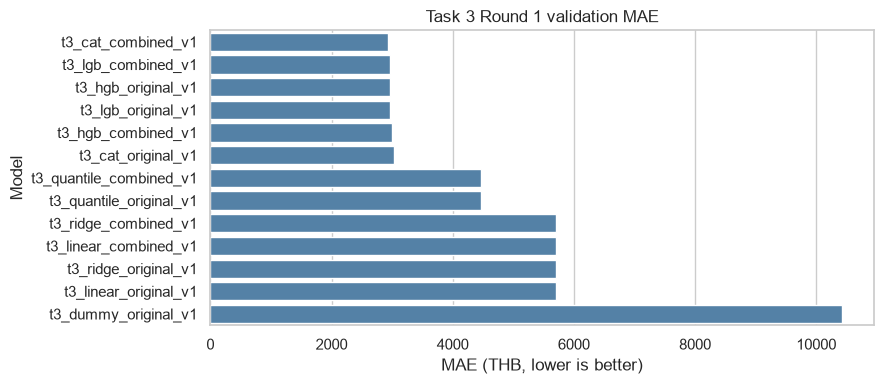

,model,original_MAE,combined_MAE,delta_combined_minus_original
0,HGB,2959.57,2997.50,37.93
1,LightGBM,2960.34,2957.98,-2.36
2,Linear,5712.37,5709.54,-2.83
3,Ridge,5711.05,5708.35,-2.70
4,Quantile,4463.87,4459.36,-4.51
5,CatBoost,3022.91,2928.48,-94.44


In [17]:
round1_names = [
    "t3_dummy_original_v1", "t3_hgb_original_v1",
    "t3_hgb_combined_v1", "t3_lgb_original_v1", "t3_lgb_combined_v1",
    "t3_linear_original_v1", "t3_linear_combined_v1",
    "t3_ridge_original_v1", "t3_ridge_combined_v1",
    "t3_quantile_original_v1", "t3_quantile_combined_v1",
    "t3_cat_original_v1", "t3_cat_combined_v1",
]
index = read_evaluation_index(3)["evaluations"]
assert all(name in index and index[name]["metric"] == "MAE_thb" for name in round1_names)
ranking_rows = []
for name in round1_names:
    model_card = json.loads(model_paths(name)[1].read_text(encoding="utf-8"))
    dataset = next(k for k, v in DATA_NAMES.items() if v == model_card["data_name"])
    pred, mae = score_validation(load_model(name), dataset)
    assert abs(mae - index[name]["score"]) < 1e-8
    zero_mask = y_valid.to_numpy() == 0
    ranking_rows.append({
        "name": name, "dataset": dataset, "MAE_thb": mae,
        "MAE_zero": float(np.abs(pred[zero_mask]).mean()),
        "MAE_clipped_zero": float(mean_absolute_error(y_valid, np.maximum(pred, 0))),
        "MAE_positive": float(np.abs(y_valid.to_numpy()[~zero_mask] - pred[~zero_mask]).mean()),
        "negative_predictions": int((pred < 0).sum()),
    })
ranking = pd.DataFrame(ranking_rows).sort_values("MAE_thb").reset_index(drop=True)
display(ranking.round(2))
print("Best Round 1 model:", ranking.iloc[0]["name"])
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=ranking, x="MAE_thb", y="name", color="steelblue", ax=ax)
ax.set(title="Task 3 Round 1 validation MAE", xlabel="MAE (THB, lower is better)",
       ylabel="Model")
plt.tight_layout()
plt.show()
matched = pd.DataFrame([
    {"model": family, "original_MAE": index[original]["score"],
     "combined_MAE": index[combined]["score"],
     "delta_combined_minus_original": index[combined]["score"] - index[original]["score"]}
    for family, original, combined in [
        ("HGB", "t3_hgb_original_v1", "t3_hgb_combined_v1"),
        ("LightGBM", "t3_lgb_original_v1", "t3_lgb_combined_v1"),
        ("Linear", "t3_linear_original_v1", "t3_linear_combined_v1"),
        ("Ridge", "t3_ridge_original_v1", "t3_ridge_combined_v1"),
        ("Quantile", "t3_quantile_original_v1", "t3_quantile_combined_v1"),
        ("CatBoost", "t3_cat_original_v1", "t3_cat_combined_v1"),
    ]
])
display(matched.round(2))

## 6. Inspect the leading model

Winner: t3_cat_combined_v1 | MAE: 2928.48 THB


,rows,actual_median,prediction_median,MAE_thb
spending_band,,,,
zero,10010,0.00,0.00,1743.64
1–1k,3323,294.64,0.00,281.20
1k–10k,4652,2524.26,2172.87,700.25
10k–50k,1118,31410.64,32132.18,4728.41
50k+,1697,86584.02,80625.90,20023.66


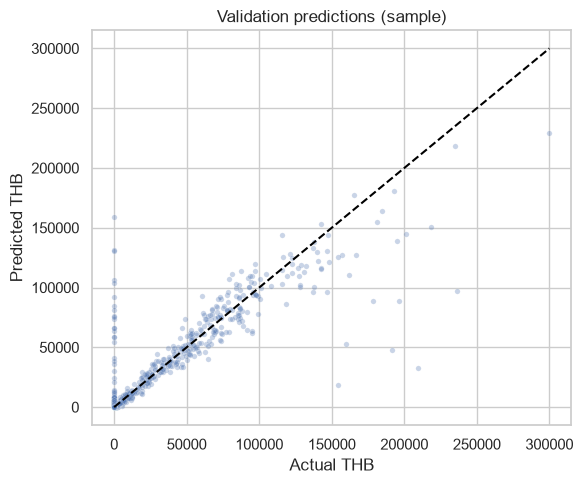

In [18]:
winner_name = ranking.iloc[0]["name"]
winner_dataset = ranking.iloc[0]["dataset"]
winner_model = load_model(winner_name)
winner_pred, winner_mae = score_validation(winner_model, winner_dataset)
print("Winner:", winner_name, "| MAE:", round(winner_mae, 2), "THB")
diagnostic = pd.DataFrame({
    "actual": y_valid.to_numpy(), "prediction": winner_pred,
    "absolute_error": np.abs(y_valid.to_numpy() - winner_pred),
})
diagnostic["spending_band"] = pd.cut(
    diagnostic["actual"], bins=[-1, 0, 1000, 10000, 50000, np.inf],
    labels=["zero", "1–1k", "1k–10k", "10k–50k", "50k+"])
display(diagnostic.groupby("spending_band", observed=True).agg(
    rows=("actual", "size"), actual_median=("actual", "median"),
    prediction_median=("prediction", "median"),
    MAE_thb=("absolute_error", "mean")).round(2))
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(data=diagnostic.sample(n=2500, random_state=SEED),
                x="actual", y="prediction", alpha=.3, s=15, ax=ax)
ax.plot([0, 300000], [0, 300000], color="black", linestyle="--")
ax.set(title="Validation predictions (sample)", xlabel="Actual THB", ylabel="Predicted THB")
plt.tight_layout()
plt.show()

Loaded permutation importance: t3_cat_combined_v1


,feature,MAE_increase,std
0,historical_spending,3931.15,183.39
1,segment,3027.00,94.71
2,prev_month_spending,2317.42,101.99
3,vip_status,480.61,57.18
4,discount_value_interaction,456.68,39.65
5,days_since_last_purchase,340.13,25.41
6,is_premium_member,270.72,51.95
7,seasonal_spending_pattern,139.38,24.52
8,games_played,119.24,5.79
9,purchase_frequency,44.88,11.73


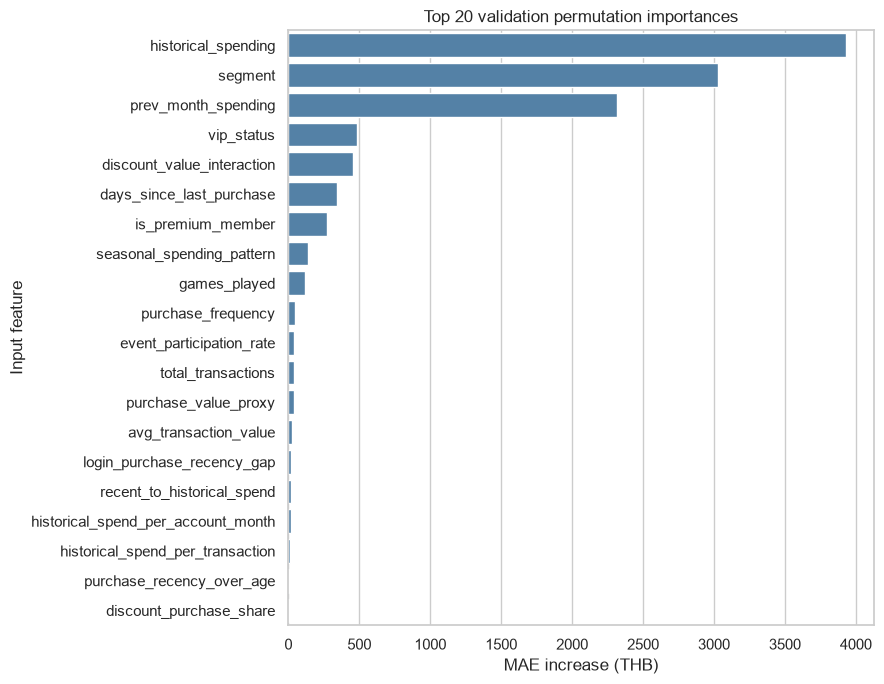

In [19]:
winner_train = train_original if winner_dataset == "original" else train_combined
winner_features = raw_features if winner_dataset == "original" else combined_features
importance_path = SRC / "task3" / "models" / ".cache" / f"{winner_name}-permutation-v1.json"
model_path = model_paths(winner_name)[0]
data_card = original_card if winner_dataset == "original" else combined_card
cache_key = {"model_mtime_ns": model_path.stat().st_mtime_ns,
             "data_created_at": data_card["created_at"], "seed": SEED,
             "rows": 1200, "repeats": 2}
cached = json.loads(importance_path.read_text(encoding="utf-8")) if importance_path.exists() else None
if cached is not None and cached.get("key") == cache_key:
    feature_ranking = pd.DataFrame(cached["ranking"])
    print("Loaded permutation importance:", winner_name)
else:
    sample_idx = pd.Series(valid_idx).sample(n=1200, random_state=SEED).to_numpy()
    sample_X = winner_train.iloc[sample_idx][winner_features]
    sample_y = y.iloc[sample_idx]
    # Scoring by negative MAE, matching the ranking direction.
    importance = permutation_importance(
        winner_model, sample_X, sample_y, scoring="neg_mean_absolute_error",
        n_repeats=2, random_state=SEED, n_jobs=1)
    feature_ranking = pd.DataFrame({
        "feature": winner_features, "MAE_increase": importance.importances_mean,
        "std": importance.importances_std,
    }).sort_values("MAE_increase", ascending=False).reset_index(drop=True)
    importance_path.parent.mkdir(parents=True, exist_ok=True)
    importance_path.write_text(
        json.dumps({"key": cache_key, "ranking": feature_ranking.to_dict("records")}, indent=2),
        encoding="utf-8")
    print("Computed permutation importance:", winner_name)
display(feature_ranking.round(2))
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=feature_ranking.head(20), x="MAE_increase", y="feature",
            color="steelblue", ax=ax)
ax.set(title="Top 20 validation permutation importances",
       xlabel="MAE increase (THB)", ylabel="Input feature")
plt.tight_layout()
plt.show()

### Round 1 interpretation

The tables above compare thirteen named models on identical validation rows. The winner is a provisional **MAE_thb** leader. Compare linear and nonlinear families, original and combined features, zero and positive spending errors, and negative predictions before choosing the next experiment. NMAE remains uncomputed until the organizer's denominator is known.


## 7. Round 2 — paired development folds and feature selection

Round 1 used the same 20% validation holdout to compare thirteen models. Here we keep that holdout out of fitting and compare candidates on **five stratified folds of the 80% development portion**. This is an exploratory stability check, because Round 1 already informed the candidate list. Competition Test is never used.

All scores remain **MAE in THB**. The competition documents name NMAE but omit its denominator. A denominator constant across predictions would not change the minimizer of MAE; a row-dependent denominator could. We do not invent either objective. Every fold measures raw predictions and predictions clipped at zero. Positive-only training is a diagnostic and is still scored on *all* validation rows, including zeros.

In [20]:
from collections import Counter
from sklearn.model_selection import StratifiedKFold

CV_FOLDS = 5
TOP_COUNTS = (8, 16, 24)
cv_X = X_dev["combined"].reset_index(drop=True)
cv_y = y_dev.reset_index(drop=True)
cv_bands = spending_band.iloc[dev_idx].reset_index(drop=True)
assert len(cv_X) == len(cv_y) == len(cv_bands) == 83_200
assert (cv_y == 0).sum() > 0 and (cv_y > 0).sum() > 0
round2_cache_dir = SRC / "task3" / "models" / ".cache"
round2_summary_path = SRC / "task3" / "models" / "round2_cv_v1.json"
round2_key = {
    "seed": SEED,
    "folds": CV_FOLDS,
    "top_counts": list(TOP_COUNTS),
    "dataset": DATA_NAMES["combined"],
    "dataset_created_at": combined_card["created_at"],
    "development_rows": len(cv_X),
    "catboost": "MAE, 500 trees, depth 6, learning rate 0.05, L2 3",
    "lightgbm": "regression_l1, 400 trees, 31 leaves, learning rate 0.05",
    "feature_ranking": "training-fold permutation MAE, 500 rows, 1 repeat",
}

def round2_preprocessor(features):
    numeric = [c for c in features if c not in nominal_cols]
    nominal = [c for c in features if c in nominal_cols]
    transformers = []
    if numeric:
        transformers.append(("numeric", SimpleImputer(strategy="median", add_indicator=True), numeric))
    if nominal:
        transformers.append(("nominal", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value=-1)),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), nominal))
    return ColumnTransformer(transformers, remainder="drop", sparse_threshold=0)

def round2_catboost(features):
    return Pipeline([
        ("preprocess", round2_preprocessor(features)),
        ("regressor", CatBoostRegressor(
            loss_function="MAE", iterations=500, depth=6, learning_rate=.05,
            l2_leaf_reg=3., random_seed=SEED, thread_count=4,
            verbose=False, allow_writing_files=False)),
    ])

def round2_lightgbm():
    return Pipeline([
        ("preprocess", make_preprocessor("combined")),
        ("regressor", LGBMRegressor(
            objective="regression_l1", n_estimators=400,
            learning_rate=.05, num_leaves=31, min_child_samples=50,
            reg_lambda=1., verbosity=-1, random_state=SEED, n_jobs=4)),
    ])

def fold_row(fold, name, actual, prediction, train_rows, features):
    actual = np.asarray(actual, dtype=float)
    prediction = np.asarray(prediction, dtype=float).reshape(-1)
    assert actual.shape == prediction.shape and np.isfinite(prediction).all()
    clipped = np.maximum(prediction, 0)
    zero = actual == 0
    high = actual >= 50_000
    return {
        "fold": fold, "model": name, "features": features,
        "train_rows": train_rows, "valid_rows": len(actual),
        "MAE_thb": float(mean_absolute_error(actual, prediction)),
        "MAE_clipped_zero": float(mean_absolute_error(actual, clipped)),
        "MAE_zero": float(np.abs(prediction[zero]).mean()),
        "MAE_positive": float(np.abs(actual[~zero] - prediction[~zero]).mean()),
        "MAE_50k_plus": float(np.abs(actual[high] - prediction[high]).mean()),
        "negative_predictions": int((prediction < 0).sum()),
    }


### Fit each fold and rank features using only its training rows

The full CatBoost fit supplies training-fold permutation importances. The top 8, 16, and 24 columns are selected from that fold's ranking, then each smaller model is refitted on the same training rows. Fold validation labels are used only for scoring. Completed folds are cached so a rerun resumes without repeating expensive fits.

In [21]:
fold_results = []
fold_splitter = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
for fold, (train_pos, valid_pos) in enumerate(fold_splitter.split(cv_X, cv_bands), start=1):
    cache_path = round2_cache_dir / f"round2_cv_v1_fold{fold}.json"
    if cache_path.exists():
        fold_card = json.loads(cache_path.read_text(encoding="utf-8"))
        assert fold_card["key"] == round2_key and fold_card["fold"] == fold
        print(f"Loaded Round 2 fold {fold}")
    else:
        X_fit, y_fit = cv_X.iloc[train_pos], cv_y.iloc[train_pos]
        X_check, y_check = cv_X.iloc[valid_pos], cv_y.iloc[valid_pos]
        rows = []
        full = round2_catboost(combined_features)
        full.fit(X_fit, y_fit)
        rows.append(fold_row(fold, "cat_full", y_check, full.predict(X_check),
                             len(X_fit), len(combined_features)))

        rank_pos = np.random.default_rng(SEED + fold).choice(
            len(X_fit), size=500, replace=False)
        importance = permutation_importance(
            full, X_fit.iloc[rank_pos], y_fit.iloc[rank_pos],
            scoring="neg_mean_absolute_error", n_repeats=1,
            random_state=SEED + fold, n_jobs=1)
        feature_rank = pd.DataFrame({
            "feature": combined_features,
            "MAE_increase": importance.importances_mean,
        }).sort_values("MAE_increase", ascending=False).reset_index(drop=True)
        ordered = feature_rank["feature"].tolist()
        for count in TOP_COUNTS:
            selected = ordered[:count]
            compact = round2_catboost(selected)
            compact.fit(X_fit[selected], y_fit)
            rows.append(fold_row(fold, f"cat_top{count}", y_check,
                                 compact.predict(X_check[selected]), len(X_fit), count))

        positive = y_fit > 0
        positive_model = round2_catboost(combined_features)
        positive_model.fit(X_fit.loc[positive], y_fit.loc[positive])
        rows.append(fold_row(fold, "cat_positive_only", y_check,
                             positive_model.predict(X_check), int(positive.sum()),
                             len(combined_features)))

        lightgbm = round2_lightgbm()
        lightgbm.fit(X_fit, y_fit)
        rows.append(fold_row(fold, "lgb_full", y_check,
                             lightgbm.predict(X_check), len(X_fit),
                             len(combined_features)))

        fold_card = {
            "key": round2_key, "fold": fold,
            "feature_ranking": feature_rank.to_dict("records"),
            "scores": rows,
        }
        round2_cache_dir.mkdir(parents=True, exist_ok=True)
        cache_path.write_text(json.dumps(fold_card, indent=2) + "\n", encoding="utf-8")
        print(f"Trained Round 2 fold {fold}")
    fold_results.append(fold_card)
assert len(fold_results) == CV_FOLDS


Loaded Round 2 fold 1
Loaded Round 2 fold 2
Loaded Round 2 fold 3
Loaded Round 2 fold 4
Loaded Round 2 fold 5


### Compare paired fold scores and feature stability

Lower MAE is better. Report raw and clipped scores separately: clipping changes the prediction rule, not the fitted model. A top-feature win on one fold is weak evidence; look for a consistent paired gain and for features selected repeatedly across folds.

,model,mean_MAE,std_MAE,mean_clipped_MAE,mean_zero_MAE,mean_positive_MAE,mean_50k_plus_MAE,mean_negative_predictions
0,cat_positive_only,2978.86,88.17,2978.70,2241.74,3662.66,18722.04,77.8
1,lgb_full,3016.06,71.52,3015.85,1826.58,4119.50,20577.57,373.0
2,cat_top24,3038.20,137.15,3037.10,1835.75,4153.65,20569.44,2134.4
3,cat_top16,3039.44,117.78,3038.40,1830.34,4161.07,20582.70,1739.8
4,cat_full,3059.59,107.30,3058.59,1834.06,4196.46,20766.03,2284.2
5,cat_top8,3149.04,111.72,3148.50,1811.18,4390.12,21685.37,976.8


model,cat_full,cat_positive_only,cat_top16,cat_top24,cat_top8,lgb_full
fold,,,,,,
1,2928.79,2896.28,3017.97,2903.29,3060.30,2944.97
2,3046.71,3062.91,3155.19,3270.27,3212.76,3067.06
3,3001.40,2874.61,2856.57,3000.76,3001.57,2931.83
4,3210.61,3007.21,3037.55,3008.45,3261.43,3079.80
5,3110.43,3053.29,3129.89,3008.20,3209.13,3056.64


,cat_positive_only,cat_top16,cat_top24,cat_top8,lgb_full
fold,,,,,
1,-32.51,89.18,-25.50,131.51,16.18
2,16.20,108.47,223.56,166.04,20.35
3,-126.79,-144.82,-0.64,0.17,-69.57
4,-203.40,-173.06,-202.15,50.82,-130.80
5,-57.13,19.47,-102.23,98.71,-53.78


Paired mean difference from full CatBoost (positive means worse):


,delta_MAE_thb
cat_positive_only,-80.73
lgb_full,-43.53
cat_top24,-21.39
cat_top16,-20.15
cat_top8,89.45


Full CatBoost clipping change by fold:


,clipped_minus_raw
fold,
1,-0.77
2,-0.97
3,-1.06
4,-0.99
5,-1.22


,feature,top8_fold_count
0,historical_spending,5
1,segment,5
2,prev_month_spending,5
3,days_since_last_purchase,5
4,discount_value_interaction,5
5,vip_status,5
6,is_premium_member,4
7,games_played,2
8,purchase_value_proxy,2
9,seasonal_spending_pattern,1


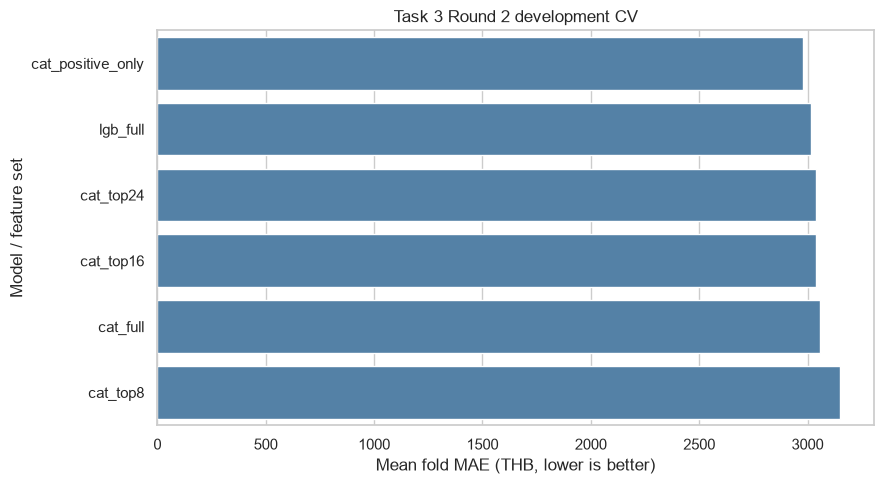

Loaded Round 2 CV record: C:\Users\BTCOM\Desktop\ml-final\src\task3\models\round2_cv_v1.json


In [22]:
round2_rows = pd.DataFrame([
    row for result in fold_results for row in result["scores"]
])
assert len(round2_rows) == CV_FOLDS * (len(TOP_COUNTS) + 3)
round2_summary = (round2_rows.groupby("model", as_index=False)
    .agg(mean_MAE=("MAE_thb", "mean"), std_MAE=("MAE_thb", "std"),
         mean_clipped_MAE=("MAE_clipped_zero", "mean"),
         mean_zero_MAE=("MAE_zero", "mean"),
         mean_positive_MAE=("MAE_positive", "mean"),
         mean_50k_plus_MAE=("MAE_50k_plus", "mean"),
         mean_negative_predictions=("negative_predictions", "mean"))
    .sort_values("mean_MAE").reset_index(drop=True))
display(round2_summary.round(2))

paired = round2_rows.pivot(index="fold", columns="model", values="MAE_thb")
paired_clipped = round2_rows.pivot(index="fold", columns="model", values="MAE_clipped_zero")
display(paired.round(2))
comparisons = pd.DataFrame({
    name: paired[name] - paired["cat_full"]
    for name in paired.columns if name != "cat_full"
})
display(comparisons.round(2))
print("Paired mean difference from full CatBoost (positive means worse):")
display(comparisons.mean().sort_values().round(2).to_frame("delta_MAE_thb"))
print("Full CatBoost clipping change by fold:")
display((paired_clipped["cat_full"] - paired["cat_full"]).round(2).to_frame("clipped_minus_raw"))

frequency = Counter(
    feature for result in fold_results
    for feature in [row["feature"] for row in result["feature_ranking"][:8]]
)
feature_stability = pd.DataFrame(frequency.most_common(),
                                 columns=["feature", "top8_fold_count"])
display(feature_stability)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=round2_summary, x="mean_MAE", y="model", color="steelblue", ax=ax)
ax.set(title="Task 3 Round 2 development CV", xlabel="Mean fold MAE (THB, lower is better)",
       ylabel="Model / feature set")
plt.tight_layout()
plt.show()

if round2_summary_path.exists():
    saved_round2 = json.loads(round2_summary_path.read_text(encoding="utf-8"))
    assert saved_round2["key"] == round2_key and saved_round2["fold_scores"] == round2_rows.to_dict("records")
    print("Loaded Round 2 CV record:", round2_summary_path)
else:
    record = {
        "name": "round2_cv_v1", "task": "task3",
        "card": "Five paired development folds; fold-local feature ranking and zero-target ablation",
        "key": round2_key,
        "metric_note": "MAE_thb only; official NMAE denominator unavailable",
        "fold_scores": round2_rows.to_dict("records"),
        "summary": round2_summary.to_dict("records"),
        "feature_top8_frequency": feature_stability.to_dict("records"),
        "feature_rankings": {str(r["fold"]): r["feature_ranking"] for r in fold_results},
    }
    round2_summary_path.write_text(json.dumps(record, indent=2) + "\n", encoding="utf-8")
    print("Saved Round 2 CV record:", round2_summary_path)


### Check the positive-only candidate on the existing Round 1 holdout

The development folds favor positive-only CatBoost in four of five folds. Fit it on positive development rows only, then score **every** original holdout row, including zeros. The saved pipeline still reads the linked combined EDA test schema. This holdout has already informed earlier model choices, so treat the result as another exploratory check rather than an untouched confirmation.

In [23]:
name = "t3_cat_combined_positive_only_v1"
positive_dev = y_dev > 0
assert 0 < positive_dev.sum() < len(y_dev)
if saved_result(name, "combined") is None:
    model = round2_catboost(combined_features)
    model.fit(X_dev["combined"].loc[positive_dev], y_dev.loc[positive_dev])
    save_model(
        task=3, name=name, model=model, data_name=DATA_NAMES["combined"],
        card={"idea": "CatBoost MAE on positive development targets only; evaluated on all holdout targets",
              "seed": SEED, "positive_train_rows": int(positive_dev.sum()),
              "split": "original stratified 80/20", "metric_note": "MAE_thb proxy; NMAE denominator unavailable"})
    pred, mae = score_validation(model, "combined")
    evaluate_model(
        task=3, name=name, score=mae, metric_name="MAE_thb",
        higher_is_better=False,
        card={"split": "all original holdout rows, including zero targets", "seed": SEED,
              "note": "MAE proxy; official NMAE denominator unavailable"})
    print(f"Trained {name}: holdout MAE = {mae:.2f} THB")
else:
    model = load_model(name)

holdout_rows = []
for candidate in ["t3_cat_combined_v1", "t3_lgb_combined_v1", name]:
    candidate_model = model if candidate == name else load_model(candidate)
    prediction = candidate_model.predict(X_valid["combined"])
    holdout_rows.append(fold_row("holdout", candidate,
                                 y_valid, prediction,
                                 int(positive_dev.sum()) if candidate == name else len(y_dev),
                                 len(combined_features)))
holdout_comparison = pd.DataFrame(holdout_rows).sort_values("MAE_thb")
display(holdout_comparison.round(2))
print("Positive development rows:", int(positive_dev.sum()))


Loaded t3_cat_combined_positive_only_v1: MAE = 2934.48 THB


,fold,model,features,train_rows,valid_rows,MAE_thb,MAE_clipped_zero,MAE_zero,MAE_positive,MAE_50k_plus,negative_predictions
0,holdout,t3_cat_combined_v1,48,83200,20800,2928.48,2927.55,1743.64,4027.66,20023.66,2514
2,holdout,t3_cat_combined_positive_only_v1,48,43161,20800,2934.48,2934.38,2134.94,3676.23,18959.42,109
1,holdout,t3_lgb_combined_v1,48,83200,20800,2957.98,2957.77,1733.35,4094.08,20506.72,480


Positive development rows: 43161


### Round 2 interpretation

- Across five development folds, positive-only CatBoost has the lowest mean MAE (**2,978.86 THB**) and beats full CatBoost in **4/5** paired folds. It improves positive-target and high-spend errors, but worsens zero-target error. On the original 20% holdout it scores **2,934.48 THB**, slightly worse than full CatBoost's **2,928.48 THB**. Keep the full CatBoost as the saved holdout leader for now.
- LightGBM full averages **3,016.06 THB**, beating full CatBoost's **3,059.59 THB** across development folds, despite losing on the original holdout. This reversal argues against treating the Round 1 ranking as stable.
- Top 24 features average **3,038.20 THB** and improve in 4/5 folds but have one large loss; top 16 are similarly mixed. Top 8 average **3,149.04 THB** and do not beat full CatBoost on any fold. Thus the six features selected in the top eight of all five folds are predictive anchors, not a sufficient model by themselves.
- Clipping negative full-CatBoost predictions improves each development fold by about **0.8–1.2 THB**, a small and consistent change. The original holdout gain was **0.93 THB**.
- `historical_spending`, `segment`, `prev_month_spending`, `days_since_last_purchase`, `discount_value_interaction`, and `vip_status` appear in every fold's top eight. Fold recurrence measures predictive stability, not operational availability. The dataset has no row-level cutoff timestamp to prove when these fields become known.

**Decision:** No new EDA dataset or full-label refit yet. Keep the existing Task 3 submission model while testing a zero-aware two-stage candidate or a simple CatBoost/LightGBM blend in a later round. Scores remain MAE in THB; the official NMAE denominator is absent from the supplied documents. Competition Test was not used in these experiments.
